# Implementacion Algoritmo - Programacion dinamica (memorization)

In [2]:
import time

In [3]:
class Tarea:
    def __init__(self, id: str, tiempo: int, prioridad: int, dependencias: list[str]):
        self.id = id
        self.tiempo = tiempo
        self.prioridad = prioridad
        self.dependencias = dependencias

    def __repr__(self):
        return str(self.id)

### Complejidades

- #### Metodo __init__
    - complejidad temporal: O(1)
    - complejidad espacial: O(1)
- #### Metodo __repr__
    - complejidad temporal: O(1)
    - complejidad espacial: O(1)

In [4]:
def dp_servidores_memo(tareas: list[Tarea], num_servidores: int):
    total_tareas = len(tareas)
    memo = {}

    def resolver(completadas: set, fin_servidor: tuple, fin_tarea: dict):
        estado_servidores = tuple(sorted(fin_servidor))
        estado_key = (frozenset(completadas), estado_servidores)

        if estado_key in memo:
            return memo[estado_key]

        if len(completadas) == total_tareas:
            tiempo_max = max(fin_servidor, default=0)
            return (tiempo_max, 0, [], [])

        disponibles = [
            t for t in tareas 
            if t.id not in completadas and all(dep in completadas for dep in t.dependencias)
        ]

        mejor_tiempo = float("inf")
        mejor_costo = float("inf")
        mejor_orden = []
        mejor_asignaciones = []

        for tarea in disponibles:
            fin_deps = max((fin_tarea[dep] for dep in tarea.dependencias), default=0)

            for s in range(num_servidores):
                inicio = max(fin_servidor[s], fin_deps)
                fin = inicio + tarea.tiempo

                nuevos_servidores = list(fin_servidor)
                nuevos_servidores[s] = fin
                completadas.add(tarea.id)
                fin_tarea[tarea.id] = fin

                t_sub, c_sub, ord_sub, asig_sub = resolver(
                    completadas, tuple(nuevos_servidores), fin_tarea
                )

                costo_actual = tarea.prioridad * fin + c_sub

                if t_sub < mejor_tiempo or (t_sub == mejor_tiempo and costo_actual < mejor_costo):
                    mejor_tiempo = t_sub
                    mejor_costo = costo_actual
                    mejor_orden = [tarea] + ord_sub
                    mejor_asignaciones = [s] + asig_sub

                completadas.remove(tarea.id)
                del fin_tarea[tarea.id]

        resultado = (mejor_tiempo, mejor_costo, mejor_orden, mejor_asignaciones)
        memo[estado_key] = resultado
        return resultado

    tiempo_total, costo_total, orden, asignacion = resolver(
        completadas=set(), 
        fin_servidor=tuple([0] * num_servidores), 
        fin_tarea={}
    )

    return (tiempo_total, orden, tuple(asignacion))

### Complejidades

- #### Método "dp_servidores_memo"
    - complejidad temporal: O(s · n · m (n + m log m))
    - complejidad espacial: O(s · (n + m))

- #### Método "resolver"
    - complejidad temporal: O(s · n · m (n + m log m))
    - complejidad espacial: O(n² + m)

# Pruebas

In [5]:
servidores_pequeño = 2
tareas_pequeño = [
    Tarea("A", 5, 2, []),
    Tarea("B", 3, 1, ["A"]),
    Tarea("C", 4, 3, ["A"]),
    Tarea("D", 2, 1, ["B", "C"]),
]

In [6]:
servidores_mediano = 3
tareas_mediano = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
]

In [7]:
servidores_grande = 3
tareas_grande = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
    Tarea("J", 9, 1, ["B"]),
]

In [8]:
servidores_xl = 3
tareas_xl = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
    Tarea("J", 9, 1, ["B"]),
    Tarea("K", 6, 2, []),
    Tarea("L", 11, 3, ["K"]),
    Tarea("M", 4, 1, ["J", "K"]),
    Tarea("N", 7, 2, ["H"]),
    Tarea("O", 3, 3, ["L", "F"]),
    Tarea("P", 12, 1, ["M"]),
    Tarea("Q", 5, 2, ["I", "O"]),
    Tarea("R", 9, 3, ["N", "P"]),
    Tarea("S", 2, 1, ["Q"]),
    Tarea("T", 8, 2, ["R", "S"]),
]

In [9]:
casos = [
    ("Pequeño", tareas_pequeño, servidores_pequeño),
    ("Mediano", tareas_mediano, servidores_mediano),
    ("Grande", tareas_grande, servidores_grande),
    ("Muy grande", tareas_xl, servidores_xl),
]

for nombre, tareas, servidores in casos:
    inicio = time.perf_counter()
    resultado = dp_servidores_memo(tareas, servidores)
    fin = time.perf_counter()
    print(f"{nombre} (Programacion_dinamica): {resultado}")
    print(f"Tiempo: {fin - inicio:.6f} segundos\n")

Pequeño (Programacion_dinamica): (11, [A, B, C, D], (0, 0, 1, 0))
Tiempo: 0.000066 segundos

Mediano (Programacion_dinamica): (32, [B, A, C, D, E, F, G, H, I], (0, 1, 1, 2, 0, 1, 0, 1, 0))
Tiempo: 0.024078 segundos

Grande (Programacion_dinamica): (32, [B, A, C, D, E, F, G, H, I, J], (0, 1, 1, 2, 0, 1, 0, 1, 0, 2))
Tiempo: 0.111189 segundos

Muy grande (Programacion_dinamica): (57, [B, A, C, F, D, E, K, L, G, J, M, I, O, P, H, N, R, Q, S, T], (0, 1, 1, 0, 1, 1, 2, 2, 2, 1, 1, 1, 2, 0, 2, 2, 0, 1, 1, 0))
Tiempo: 151.092002 segundos



# Grafica

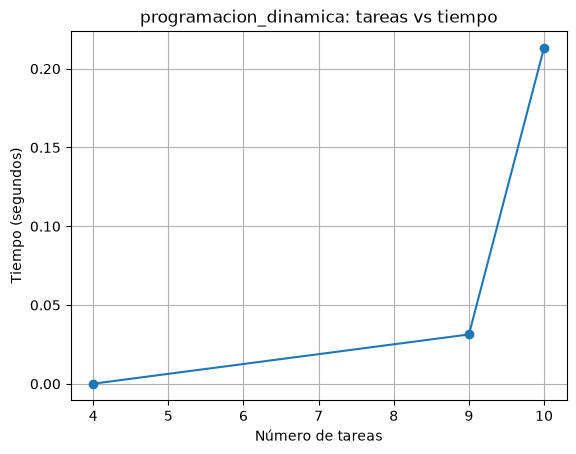

In [ ]:
import matplotlib.pyplot as plt

tareas = [4, 9, 10]
tiempos = [0.000079, 0.031330, 0.213334]

plt.plot(tareas, tiempos, marker="o")
plt.xlabel("Número de tareas")
plt.ylabel("Tiempo (segundos)")
plt.title("programacion_dinamica: tareas vs tiempo")
plt.grid(True)
plt.show()